In [ ]:
pip install lightgbm

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import lightgbm as lgb
import numpy as np

In [ ]:
# Load dataset
df = pd.read_csv("StudentPerformanceFactors.csv")


In [ ]:
# Set target column
target = "Exam_Score"

In [ ]:
# Encode categorical columns
df = pd.get_dummies(df, drop_first=True)


In [ ]:
# Split features/target
X = df.drop(columns=[target]).values
y = df[target].values

In [ ]:
# Train/Val/Test split (60/20/20)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)


In [ ]:
# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)


In [ ]:
# Build LightGBM model
model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=1000,
    learning_rate=0.012,
    num_leaves=40,
    max_depth=4,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    early_stopping_rounds=50
)

In [ ]:
# Train model
model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="l2"
)

[LightGBM] [Warning] early_stopping_round is set=50, early_stopping_rounds=50 will be ignored. Current value: early_stopping_round=50
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000779 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 224
[LightGBM] [Info] Number of data points in the train set: 3964, number of used features: 27
[LightGBM] [Warning] early_stopping_round is set=50, early_stopping_rounds=50 will be ignored. Current value: early_stopping_round=50
[LightGBM] [Info] Start training from score 67.214934
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits wi

LGBMRegressor(colsample_bytree=0.85, early_stopping_rounds=50,
              learning_rate=0.012, max_depth=4, n_estimators=1000,
              num_leaves=40, objective='regression', random_state=42,
              reg_alpha=0.1, reg_lambda=1.0, subsample=0.85)

[LightGBM] [Warning] early_stopping_round is set=50, early_stopping_rounds=50 will be ignored. Current value: early_stopping_round=50
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001238 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 224
[LightGBM] [Info] Number of data points in the train set: 3964, number of used features: 27
[LightGBM] [Warning] early_stopping_round is set=50, early_stopping_rounds=50 will be ignored. Current value: early_stopping_round=50
[LightGBM] [Info] Start training from score 67.214934
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits wi

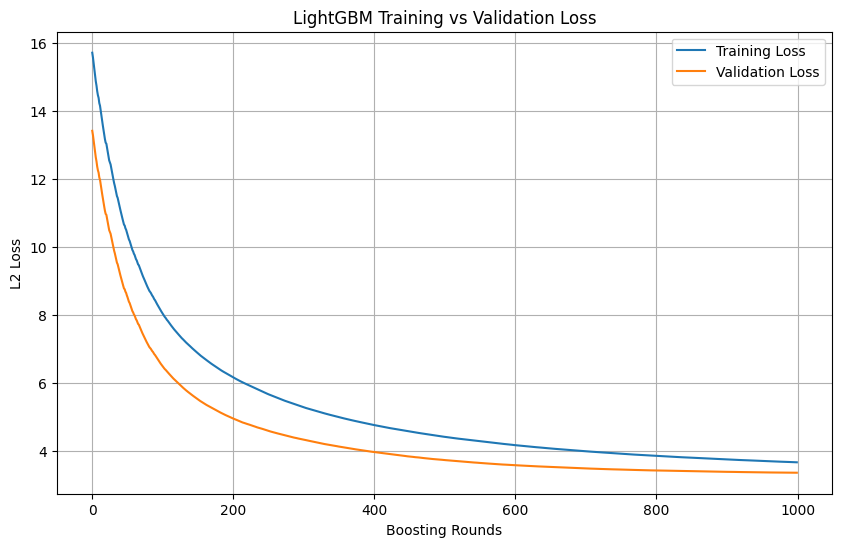

In [ ]:
import matplotlib.pyplot as plt
import time

# Track training time
start_time = time.time()

model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    eval_names=["training", "valid_0"],
    eval_metric="l2"
)

end_time = time.time()
training_time = end_time - start_time
print(f"Training time: {training_time:.2f} seconds")

# Extract training history
results = model.evals_result_

train_loss = results["training"]["l2"]
val_loss = results["valid_0"]["l2"]

# Plot training vs validation loss
plt.figure(figsize=(10,6))
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.xlabel("Boosting Rounds")
plt.ylabel("L2 Loss")
plt.title("LightGBM Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# Predict on test set
y_pred = model.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [ ]:
# Evaluate
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test R²:", r2)


Test MSE: 4.3092729582864555
Test RMSE: 2.075878839982347
Test R²: 0.6998408104235192
